# Smart Shelf - Milestone 2, Task M2-T07: Design decision, risk input for Track 3B

**Task card:** Track 3B uses Track 3A's out-of-fold predicted spoilage probability as its risk input (not `spoilage_risk`), so it works for any new batch in Simulator Mode and avoids leakage. M3-T04 follows M3-T02, so the probabilities come from the final tuned classifier, and the M3-T05 controls match. To finish: document the decision, and how the out-of-fold predictions are produced, in the Feature Engineering Summary.

The decision was already made, so the deliverable is the documentation: `M2-T07_Design_Decision.md`. This notebook is the **evidence** behind it. It builds a small prototype of Track 3A (the real classifier comes from M3-T02) and uses it to answer four questions with numbers from the real file:

1. Is `spoilage_risk` really a bad input? What exactly is wrong with it? (Section 2)
2. What goes wrong if Track 3B uses ordinary predictions on the training rows? (Section 3)
3. How are the out-of-fold predictions produced, and are they correct? (Sections 4 and 5)
4. Which fold scheme and which K, and what happens for a new batch in Simulator Mode? (Sections 6 and 7)

**Decisions made in this notebook:**

| # | Decision |
|---|---|
| 1 | Track 3B's risk input is the out-of-fold probability for training batches and the final classifier's probability for new batches. `spoilage_risk` is not used. |
| 2 | Out-of-fold scheme: stratified, shuffled 5-fold on the training rows (Section 6). |
| 3 | Re-check rule for M3-T04: repeat the Section 6 comparison with the tuned classifier. If the out-of-fold and holdout AUC differ by more than 0.01, switch to time-blocked folds. |

## 0. Imports and loading the data

In [1]:
import os, hashlib
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.base import clone
from sklearn.ensemble import HistGradientBoostingClassifier, HistGradientBoostingRegressor, RandomForestClassifier
from sklearn.metrics import roc_auc_score, average_precision_score, r2_score
from sklearn.model_selection import StratifiedKFold, KFold, GroupKFold, cross_val_predict

sns.set_theme(style="whitegrid")
os.makedirs("figures", exist_ok=True)

In [2]:
# put the csv in the same folder as this notebook
DATA_PATH = Path("perishable_goods_management.csv")
EXPECTED_SHA = "de94302b867c9debedfd45c431306623fdfc038f5ed8ca17736339b4460a6674"   # file verified in M1-T01

print("same file as verified in M1-T01:", hashlib.sha256(DATA_PATH.read_bytes()).hexdigest() == EXPECTED_SHA)

df = pd.read_csv(DATA_PATH, parse_dates=["transaction_date", "expiration_date"])
assert df.shape == (100_000, 42), "Unexpected shape"
print(df.shape, "| spoilage rate:", round(df["was_spoiled"].mean(), 3))

same file as verified in M1-T01: True
(100000, 42) | spoilage rate: 0.194


## 1. The decision in simple words

- **Track 3A** is the classifier: it looks at a batch and predicts the probability that it will spoil.
- **Track 3B** is the revenue and discount model: it needs one number that says how risky a batch is.

Two candidates for that number:

| Option | Problem |
|---|---|
| The `spoilage_risk` column | It comes from the data-generating process behind `was_spoiled` (Milestone 1 treats it as an evaluation benchmark only). A user who types a new batch into Simulator Mode has no `spoilage_risk` value to give. |
| Track 3A's predicted probability | It can be computed for any batch from information known when the batch arrives. |

**Decision 1: Track 3B uses Track 3A's probability.** There is one catch: for the **training** batches, Track 3A has already seen the answers while learning, so its predictions on those same rows are too good. The fix is out-of-fold predictions (Section 3). Section 2 first looks at what is really wrong with `spoilage_risk`.

## 2. Prototype setup

To test anything, a classifier is needed. This one is a **prototype**: simple inputs, light settings, no tuning. The real features and tuning belong to M3-T02. Its job here is to show how the procedure behaves.

**Inputs** (known when the batch arrives): shelf life and days remaining, storage temperature and deviation, temperature abuse events, handling, packaging and supplier scores, distribution hours, demand, quantity, prices, `spoilage_sensitivity` (cleared in M1-T06), `is_promoted`, `quality_grade`, `category`, and the remaining shelf-life ratio from M2-T02.

**Left out, with reasons:**

| Left out | Why |
|---|---|
| `spoilage_risk` | the subject of this task |
| `units_sold`, `units_wasted`, `waste_pct`, `waste_cost`, `revenue`, `profit`, `profit_margin_pct` | results, known only after the batch is sold |
| `markdown_applied`, `discount_pct`, `selling_price` | discount treatments, flagged `exclude (treatment)` for Track 3A in M1-T04 |
| `product_id` | 45,301 identifier-like values |
| calendar columns, region, store, supplier id | no effect found in Milestone 1 (kept out to keep the prototype simple) |

**Split:** the same time-ordered split as M1-T04: training up to 2024-08-07, holdout after. The holdout plays the role of **new batches arriving later**.

In [3]:
numeric_inputs = ["shelf_life_days", "days_remaining_at_purchase", "storage_temp", "temp_deviation", "temp_abuse_events",
                  "handling_score", "packaging_score", "supplier_score", "distribution_hours", "daily_demand",
                  "demand_variability", "initial_quantity", "base_price", "cost_price", "spoilage_sensitivity", "is_promoted"]

X = df[numeric_inputs].copy()
X["expiry_remaining_ratio"] = (df["days_until_expiry"] / df["shelf_life_days"]).clip(0, 1)       # same as M2-T02
X["quality_grade_ord"] = df["quality_grade"].map({"C": 1, "B": 2, "A": 3})                        # same coding as M1-T04
X = pd.concat([X, pd.get_dummies(df["category"], prefix="cat", dtype=int)], axis=1)
y = df["was_spoiled"]

is_train = df["transaction_date"] <= "2024-08-07"
X_train, y_train = X[is_train].reset_index(drop=True), y[is_train].reset_index(drop=True)
X_hold, y_hold = X[~is_train], y[~is_train]
train_df = df[is_train].reset_index(drop=True)

print("input columns:", X.shape[1])
print("training rows:", len(X_train), "| spoilage rate", round(y_train.mean(), 4))
print("holdout rows: ", len(X_hold), "| spoilage rate", round(y_hold.mean(), 4))
assert len(X_train) == 80_042 and len(X_hold) == 19_958      # same split as M1-T04

model = HistGradientBoostingClassifier(max_depth=4, learning_rate=0.05, max_iter=200, min_samples_leaf=100,
                                       l2_regularization=1.0, random_state=42)

input columns: 28
training rows: 80042 | spoilage rate 0.1935
holdout rows:  19958 | spoilage rate 0.1981


### 2.1 What is wrong with `spoilage_risk`?

Three numbers on the real file:

1. **AUC of `spoilage_risk` alone** (0.5 = coin flip, 1.0 = perfect).
2. **How much of `spoilage_risk` the input columns can rebuild.** The rebuild uses out-of-fold predictions of a regression model, so it is honest. If the column is almost completely explained by pre-sale inputs, it behaves like a hidden formula over them.
3. **Does the leftover part (what the inputs cannot rebuild) say anything about the outcome?** If `spoilage_risk` contained outcome information, the leftover would predict `was_spoiled`.

In [4]:
risk = df["spoilage_risk"]
print("AUC of spoilage_risk alone:", round(roc_auc_score(y, risk), 4))

regressor = HistGradientBoostingRegressor(max_depth=5, max_iter=300, learning_rate=0.08, random_state=0)
rebuilt = cross_val_predict(regressor, X, risk, cv=KFold(5, shuffle=True, random_state=0))
print("share of spoilage_risk rebuilt from the input columns (R2, out-of-fold):", round(r2_score(risk, rebuilt), 3))

leftover = risk - rebuilt
print("AUC of the rebuilt part vs was_spoiled: ", round(roc_auc_score(y, rebuilt), 4))
print("AUC of the leftover part vs was_spoiled:", round(roc_auc_score(y, leftover), 4))

AUC of spoilage_risk alone: 0.5938
share of spoilage_risk rebuilt from the input columns (R2, out-of-fold): 0.996
AUC of the rebuilt part vs was_spoiled:  0.5936
AUC of the leftover part vs was_spoiled: 0.5149


**What this shows:** `spoilage_risk` alone has an AUC of only 0.594, and about 99.6% of it can be rebuilt from the input columns. The leftover part is almost useless for predicting the outcome (AUC 0.515). So the column does not hand the model the answer in the way a result column would. It behaves like a formula over the inputs, and its predictive power is the ceiling that the inputs allow in this dataset.

That changes the argument for the decision, so it is stated precisely:

- The reasons to avoid `spoilage_risk` are that it is a generated score tied to the same process as `was_spoiled` (Milestone 1 keeps it as a benchmark only), and that **it does not exist for a new batch** in Simulator Mode.
- The decision **loses nothing**: the input columns already contain what `spoilage_risk` contains, and a classifier trained on them recovers it (Section 5.4).

## 3. In-sample versus out-of-fold

### The problem
If the model is trained on the training rows and then asked to predict those same rows, it has already seen their answers, so the probabilities look better than they really are. If Track 3B learned from such a risk number, it would learn from numbers that are too good, and it would fail on new batches.

The size of the problem depends on how flexible the model is. Two models are compared: the light prototype, and a very flexible random forest that memorises its training rows.

In [5]:
light_model = clone(model).fit(X_train, y_train)
flexible_model = RandomForestClassifier(n_estimators=100, min_samples_leaf=1, random_state=42, n_jobs=-1).fit(X_train, y_train)

rows = []
for name, m in [("light prototype", light_model), ("very flexible random forest", flexible_model)]:
    rows.append({"model": name,
                 "AUC on the rows it trained on (in-sample)": roc_auc_score(y_train, m.predict_proba(X_train)[:, 1]),
                 "AUC on later batches it never saw (holdout)": roc_auc_score(y_hold, m.predict_proba(X_hold)[:, 1])})
pd.DataFrame(rows).round(3)

,model,AUC on the rows it trained on (in-sample),AUC on later batches it never saw (holdout)
0,light prototype,0.608,0.587
1,very flexible random forest,1.000,0.554


The flexible forest looks almost perfect on the rows it trained on and is close to a coin flip on new batches. If its in-sample probabilities were passed to Track 3B, the revenue model would be trained on a risk number that does not exist for new batches. The light prototype is much less affected, but the gap is still there.

### The fix: out-of-fold (OOF) predictions

Split the training rows into 5 groups (folds). Each fold is predicted by a model trained **only on the other 4 folds**:

| Round | Trained on | Predicts |
|---|---|---|
| 1 | folds 2, 3, 4, 5 | fold 1 |
| 2 | folds 1, 3, 4, 5 | fold 2 |
| 3 | folds 1, 2, 4, 5 | fold 3 |
| 4 | folds 1, 2, 3, 5 | fold 4 |
| 5 | folds 1, 2, 3, 4 | fold 5 |

At the end every training row has one probability, produced by a model that never saw that row. It is like testing a student on questions that were not in the study notes.

In [6]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)    # stratified = every fold has a similar spoilage rate

oof_proba = np.full(len(X_train), np.nan)          # start empty, so a missed row would show up as NaN
times_predicted = np.zeros(len(X_train), dtype=int)

for fold, (fit_rows, predict_rows) in enumerate(cv.split(X_train, y_train), start=1):
    fold_model = clone(model).fit(X_train.iloc[fit_rows], y_train.iloc[fit_rows])          # learn from 4 folds
    oof_proba[predict_rows] = fold_model.predict_proba(X_train.iloc[predict_rows])[:, 1]   # predict the 5th
    times_predicted[predict_rows] += 1
    print("fold", fold, ": trained on", len(fit_rows), "rows, predicted", len(predict_rows), "rows")

fold 1 : trained on 64033 rows, predicted 16009 rows
fold 2 : trained on 64033 rows, predicted 16009 rows
fold 3 : trained on 64034 rows, predicted 16008 rows
fold 4 : trained on 64034 rows, predicted 16008 rows
fold 5 : trained on 64034 rows, predicted 16008 rows


## 4. Validation of the out-of-fold predictions

### 4.1 Is every training row predicted exactly once?

In [7]:
print("rows without an OOF probability:", np.isnan(oof_proba).sum())
print("rows predicted more than once:", (times_predicted > 1).sum())
print("every row predicted exactly once:", (times_predicted == 1).all())

rows without an OOF probability: 0
rows predicted more than once: 0
every row predicted exactly once: True


### 4.2 Does the loop match scikit-learn's own function?

scikit-learn has a function that does the same job in one line (`cross_val_predict`). If the loop and the function agree, the loop is correct.

In [8]:
library_proba = cross_val_predict(clone(model), X_train, y_train, cv=cv, method="predict_proba")[:, 1]
print("loop and cross_val_predict give the same probabilities:", np.allclose(oof_proba, library_proba))

loop and cross_val_predict give the same probabilities: True


### 4.3 Are the probabilities honest, and are they on the same scale as for new batches?

The AUC of three sets of probabilities is compared, with `spoilage_risk` as the reference. The final model (trained on all the training rows) produces the probabilities for the holdout, the stand-in for new batches.

In [9]:
final_model = clone(model).fit(X_train, y_train)
in_sample_proba = final_model.predict_proba(X_train)[:, 1]
hold_proba = final_model.predict_proba(X_hold)[:, 1]

results = pd.DataFrame({
    "probabilities": ["in-sample (training rows, model saw them)",
                      "out-of-fold (training rows, model did not see them)",
                      "holdout (later batches, model did not see them)",
                      "spoilage_risk column (reference)"],
    "AUC": [roc_auc_score(y_train, in_sample_proba), roc_auc_score(y_train, oof_proba),
            roc_auc_score(y_hold, hold_proba), roc_auc_score(y_hold, df.loc[~is_train, "spoilage_risk"])],
    "PR-AUC": [average_precision_score(y_train, in_sample_proba), average_precision_score(y_train, oof_proba),
               average_precision_score(y_hold, hold_proba), average_precision_score(y_hold, df.loc[~is_train, "spoilage_risk"])],
}).round(4)
display(results)

print("spoilage rate for reference: training", round(y_train.mean(), 4), "| holdout", round(y_hold.mean(), 4))
compare = pd.DataFrame({"OOF (training rows)": pd.Series(oof_proba).describe(),
                        "holdout (new batches)": pd.Series(hold_proba).describe()})
compare.round(4)

,probabilities,AUC,PR-AUC
0,"in-sample (training rows, model saw them)",0.6079,0.2679
1,"out-of-fold (training rows, model did not see ...",0.5859,0.2437
2,"holdout (later batches, model did not see them)",0.5874,0.2498
3,spoilage_risk column (reference),0.5967,0.2550


spoilage rate for reference: training 0.1935 | holdout 0.1981


,OOF (training rows),holdout (new batches)
count,80042.0000,19958.0000
mean,0.1935,0.1939
std,0.0460,0.0441
min,0.0692,0.0904
25%,0.1596,0.1615
50%,0.1908,0.1907
75%,0.2248,0.2249
max,0.4542,0.3834


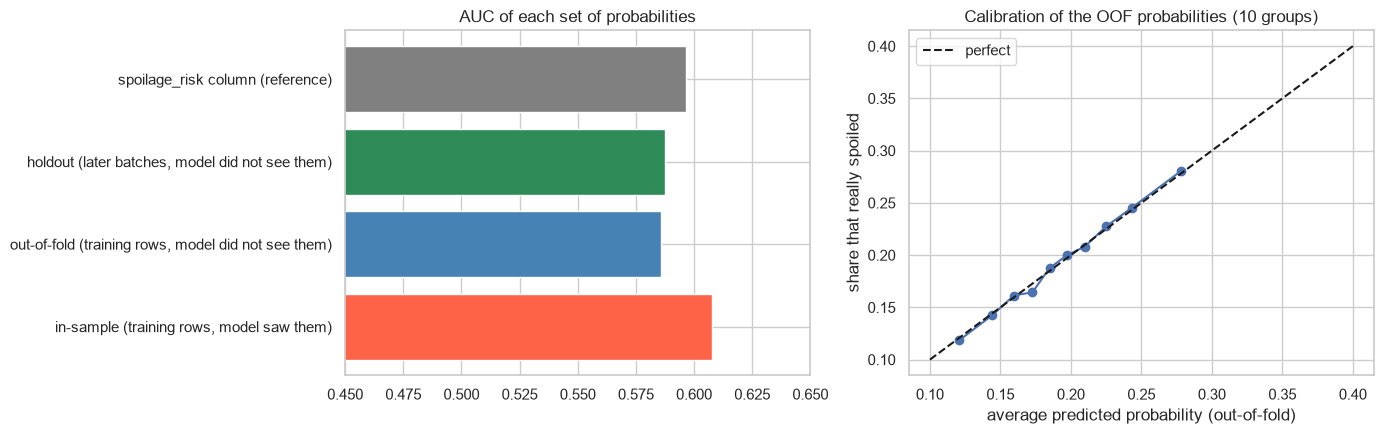

In [10]:
# calibration: when the model says about 20%, do about 20% of the batches spoil?
groups = pd.qcut(oof_proba, 10, duplicates="drop")
calibration = pd.DataFrame({"predicted": oof_proba, "actual": y_train.values}).groupby(groups, observed=True).mean()

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].barh(results["probabilities"], results["AUC"], color=["tomato", "steelblue", "seagreen", "grey"])
axes[0].set_xlim(0.45, 0.65)
axes[0].set_title("AUC of each set of probabilities")

axes[1].plot(calibration["predicted"], calibration["actual"], marker="o")
axes[1].plot([0.1, 0.4], [0.1, 0.4], "k--", label="perfect")
axes[1].set_xlabel("average predicted probability (out-of-fold)")
axes[1].set_ylabel("share that really spoiled")
axes[1].set_title("Calibration of the OOF probabilities (10 groups)")
axes[1].legend()

plt.tight_layout()
plt.savefig("figures/m2_t07_oof_check.png", dpi=150, bbox_inches="tight")
plt.show()

**What this shows:**

- The in-sample AUC (0.610) is above the out-of-fold AUC (0.586): that gap is the over-optimism that out-of-fold predictions remove.
- The out-of-fold AUC and the holdout AUC are essentially equal (0.586 and 0.587), and their probabilities have the same average and spread. So Track 3B is trained on risk numbers that look like the ones a new batch gets from the final model.
- The probabilities are on the right scale: the calibration curve follows the diagonal, so a predicted 20% really means about 20%.
- `spoilage_risk` has about the same AUC (0.597 on the holdout), so replacing it loses no ranking power.

### 4.4 Do the out-of-fold probabilities carry the same information as `spoilage_risk`?

In [11]:
print("correlation of OOF probability with spoilage_risk (training rows):", round(np.corrcoef(oof_proba, train_df["spoilage_risk"])[0, 1], 3))
print("correlation of holdout probability with spoilage_risk (holdout rows):", round(np.corrcoef(hold_proba, df.loc[~is_train, "spoilage_risk"])[0, 1], 3))

correlation of OOF probability with spoilage_risk (training rows): 0.904
correlation of holdout probability with spoilage_risk (holdout rows): 0.909


The correlation is high, which confirms the claim of Section 2.1 from the other side: the classifier rebuilds the information in `spoilage_risk` from the input columns alone, so Track 3B gets that information without needing the column.

## 5. Decision 2: which out-of-fold scheme?

Five ways to produce out-of-fold predictions are compared on the real data. Two questions decide: does the scheme give a probability for **every** training row (Track 3B needs a risk for each row), and does its AUC match the holdout (do the probabilities behave like the ones a new batch gets)?

| Scheme | Idea |
|---|---|
| Stratified 5-fold (shuffled) | random folds, each with a similar spoilage rate |
| Stratified 10-fold (shuffled) | the same with 10 folds |
| Time-blocked 5-fold | 5 blocks of consecutive dates, each predicted by a model trained on the other four |
| Expanding window | train on the past only and predict the next block (the first block is never predicted) |
| Grouped 5-fold | all batches of a `product_name` x store pair stay in the same fold |

In [12]:
def oof_from_splits(splits):
    oof = np.full(len(X_train), np.nan)
    for fit_rows, predict_rows in splits:
        m = clone(model).fit(X_train.iloc[fit_rows], y_train.iloc[fit_rows])
        oof[predict_rows] = m.predict_proba(X_train.iloc[predict_rows])[:, 1]
    return oof

# 5 blocks of consecutive dates
block = pd.qcut(train_df["transaction_date"].rank(method="first"), 5, labels=False).values
pair_group = (train_df["product_name"] + "|" + train_df["store_id"]).values

schemes = {
    "Stratified 5-fold (shuffled)": list(StratifiedKFold(5, shuffle=True, random_state=42).split(X_train, y_train)),
    "Stratified 10-fold (shuffled)": list(StratifiedKFold(10, shuffle=True, random_state=42).split(X_train, y_train)),
    "Time-blocked 5-fold": [(np.where(block != b)[0], np.where(block == b)[0]) for b in range(5)],
    "Expanding window (past only)": [(np.where(block < b)[0], np.where(block == b)[0]) for b in range(1, 5)],
    "Grouped 5-fold (product x store)": list(GroupKFold(5).split(X_train, y_train, pair_group)),
}

holdout_auc = roc_auc_score(y_hold, hold_proba)
rows = []
for name, splits in schemes.items():
    oof = oof_from_splits(splits)
    ok = ~np.isnan(oof)
    auc = roc_auc_score(y_train[ok], oof[ok])
    rows.append({"scheme": name, "rows with a probability (%)": round(ok.mean() * 100, 1),
                 "OOF AUC": round(auc, 4), "holdout AUC": round(holdout_auc, 4), "gap": round(abs(auc - holdout_auc), 4)})
scheme_table = pd.DataFrame(rows).set_index("scheme")
scheme_table

,rows with a probability (%),OOF AUC,holdout AUC,gap
scheme,,,,
Stratified 5-fold (shuffled),100.0,0.5859,0.5874,0.0014
Stratified 10-fold (shuffled),100.0,0.5863,0.5874,0.0011
Time-blocked 5-fold,100.0,0.5870,0.5874,0.0004
Expanding window (past only),80.0,0.5829,0.5874,0.0045
Grouped 5-fold (product x store),100.0,0.5868,0.5874,0.0006


In [13]:
# how uncertain is the holdout AUC itself? (bootstrap: re-draw the holdout rows 300 times)
rng = np.random.default_rng(0)
aucs = []
for _ in range(300):
    pick = rng.integers(0, len(y_hold), len(y_hold))
    aucs.append(roc_auc_score(y_hold.values[pick], hold_proba[pick]))
low, high = np.percentile(aucs, [2.5, 97.5])
print("holdout AUC", round(holdout_auc, 4), "with a 95% range of", round(low, 3), "to", round(high, 3))

holdout AUC 0.5874 with a 95% range of 0.578 to 0.597


**Decision 2: stratified, shuffled 5-fold on the training rows.**

**Reason:**

- Every scheme except the expanding window gives a probability for every training row and an AUC within 0.002 of the holdout, which is far smaller than the uncertainty of the holdout AUC itself (about plus or minus 0.01). The differences between these schemes are noise.
- The expanding window leaves the first 20% of the rows without a probability and is the furthest from the holdout, so it is rejected.
- Grouping by product and store does not change anything, which matches the Milestone 1 finding that a product-store pair carries no information of its own.
- With equal quality, the simplest and cheapest scheme wins, and 10 folds give nothing over 5.

**Decision 3 (re-check rule):** when M3-T04 produces the final probabilities with the tuned classifier, repeat this comparison. If the out-of-fold AUC and the holdout AUC differ by more than 0.01, use the time-blocked scheme instead.

## 6. The Simulator Mode path: a brand-new batch

In Simulator Mode a user enters the details of a batch that does not exist in the data. There is no `spoilage_risk` for it, and no out-of-fold prediction, because it was never part of the training rows. Its risk number comes from the **final** classifier:

`risk = final_classifier.predict_proba(new_batch)`

This is consistent with the training rows: the final classifier has never seen that batch, just as each fold model never saw its held-out fold.

As a demonstration, one real holdout batch is taken, and the same batch is scored again with poor handling and packaging.

In [14]:
batch = X_hold.iloc[[0]].copy()
worse = batch.copy()
worse["handling_score"] = 2
worse["packaging_score"] = 2

print("handling / packaging scores in the real batch:", int(batch["handling_score"].iloc[0]), "/", int(batch["packaging_score"].iloc[0]))
print("risk of the batch as it is:                  ", round(final_model.predict_proba(batch)[0, 1], 3))
print("risk with handling and packaging scores of 2:", round(final_model.predict_proba(worse)[0, 1], 3))
print("columns the simulator needs to collect:", list(batch.columns))

handling / packaging scores in the real batch: 9 / 10
risk of the batch as it is:                   0.105
risk with handling and packaging scores of 2: 0.193
columns the simulator needs to collect: ['shelf_life_days', 'days_remaining_at_purchase', 'storage_temp', 'temp_deviation', 'temp_abuse_events', 'handling_score', 'packaging_score', 'supplier_score', 'distribution_hours', 'daily_demand', 'demand_variability', 'initial_quantity', 'base_price', 'cost_price', 'spoilage_sensitivity', 'is_promoted', 'expiry_remaining_ratio', 'quality_grade_ord', 'cat_Bakery', 'cat_Beverages', 'cat_Dairy', 'cat_Deli', 'cat_Frozen_Meals', 'cat_Meat', 'cat_Pharmaceuticals', 'cat_Produce', 'cat_Ready_to_Eat', 'cat_Seafood']


Everything in that list is known when a batch arrives, and nothing needs the outcome. That is what makes the classifier's probability a valid risk input for Simulator Mode.

## 7. Summary of the evidence

| Question | Result |
|---|---|
| Does `spoilage_risk` give the model the answer? | No: AUC 0.594, and 99.6% of it is rebuilt from the input columns. The leftover part is almost useless (AUC 0.515). |
| Why not use it anyway? | It is a generated score tied to the outcome-producing process (Milestone 1 keeps it as a benchmark), and a new batch in Simulator Mode has no value for it. |
| Is anything lost by replacing it? | No: the classifier's holdout AUC (0.587) matches `spoilage_risk` (0.597) within the uncertainty (about plus or minus 0.01). |
| Why out-of-fold and not ordinary predictions? | In-sample predictions are over-optimistic. For a flexible model the AUC would be almost perfect on training rows and close to 0.5 on new batches. |
| Is the OOF procedure correct? | Every row predicted exactly once, the loop equals `cross_val_predict`, OOF and holdout AUC are equal, the probabilities are calibrated. |
| Which scheme? | Stratified, shuffled 5-fold, re-checked in M3-T04 with the tuned classifier (rule: switch to time-blocked folds if the gap exceeds 0.01). |